# TechHire — Recruitment Fairness & Governance Analysis

**6,000 applicant profiles · Disaggregated metrics · Equalized odds · Controlled ranking comparison**

This notebook generates the evaluation cohort, compares two selection policies at a fixed hiring capacity, calculates group-level fairness statistics, and creates five executive-ready figures.


## Step 0 — Environment and reproducibility

Initialize the analysis with a fixed seed and the shared metrics and chart modules.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
from IPython.display import Image, display
from src.simulation import generate_synthetic_applicants, SEED, CAPACITY_RATE
from src.metrics import all_metrics, fairness_summary
from src.charts import generate_figures

ROOT = Path.cwd()
DATA_DIR = ROOT / "data"
RESULTS_DIR = ROOT / "results"
DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
print(f"Simulation seed: {SEED} | output: {ROOT}")

Simulation seed: 20261102 | output: /mnt/data/TechHire_Fairness_Lab_Notebook_Cleaned


## Step 1 — Applicant cohort and decision policies

Generate candidate features and apply the baseline and revised screening rules at the same 35% shortlist capacity.


In [2]:
applicants = generate_synthetic_applicants()
assert len(applicants) == 6000
assert applicants["record_origin"].eq("SYNTHETIC_GENERATED_NOT_REAL").all()
assert applicants.applicant_id.is_unique
applicants.to_csv(DATA_DIR / "synthetic_applicants.csv", index=False)
print("Applicant records:", len(applicants))
print("Selections in each scenario:", applicants[["baseline_selected","mitigated_selected"]].sum().to_dict())
display(applicants.drop(columns=["name_origin_proxy","prestige_proxy","networking_proxy","record_origin"]).head(8))

Applicant records: 6000
Selections in each scenario: {'baseline_selected': 2100, 'mitigated_selected': 2100}


,applicant_id,job_family,gender,age_band,nationality_group,skills_match,experience_years,assessment_score,employment_gap_months,synthetic_merit_score,synthetic_qualified_label,baseline_score,baseline_selected,mitigated_score,mitigated_selected
0,SYN-00001,Software Engineer,Male,18-35,Non-EU,79.8,6.4,61.0,2,71.000,0,65.685,1,71.967,1
1,SYN-00002,Software Engineer,Female,18-35,Polish,65.9,5.6,90.0,8,65.825,0,64.837,1,60.254,0
2,SYN-00003,Data Analyst,Male,18-35,Polish,48.4,1.5,49.5,6,38.275,0,46.051,0,42.511,0
3,SYN-00004,Data Analyst,Male,46+,Polish,65.6,3.5,68.1,5,56.069,0,54.095,0,53.300,0
4,SYN-00005,Data Analyst,Female,36-45,Other EU,65.9,3.7,81.4,4,59.421,0,61.882,0,57.042,0
5,SYN-00006,Data Analyst,Female,36-45,Non-EU,79.3,13.7,61.5,5,85.810,1,76.960,1,81.451,1
6,SYN-00007,Cybersecurity Analyst,Male,36-45,Polish,79.3,1.0,69.1,9,56.244,0,61.672,0,56.042,0
7,SYN-00008,Cybersecurity Analyst,Male,36-45,Polish,42.8,4.0,61.7,11,41.263,0,40.928,0,42.283,0


## Step 2 — Fairness metrics

Compute selection rates, within-attribute selection ratios, confidence intervals, true/false positive rates, and opportunity gaps. A ratio below 0.80 is a review signal rather than a legal conclusion.


In [3]:
metrics = all_metrics(applicants)
metrics.to_csv(DATA_DIR / "subgroup_metrics.csv", index=False)
cols=["scenario","attribute","group","n","selected","selection_rate","selection_ratio_to_max","tpr","fpr","four_fifths_flag"]
display(metrics[cols].round(3))

,scenario,attribute,group,n,selected,selection_rate,selection_ratio_to_max,tpr,fpr,four_fifths_flag
0,Baseline,gender,Female,2799,788,0.282,0.687,0.570,0.058,True
1,Baseline,gender,Male,3201,1312,0.410,1.000,0.742,0.179,False
2,Baseline,age_band,18-35,2759,1083,0.393,1.000,0.720,0.151,False
3,Baseline,age_band,36-45,1980,742,0.375,0.955,0.694,0.144,False
4,Baseline,age_band,46+,1261,275,0.218,0.556,0.471,0.033,True
5,Baseline,nationality_group,Polish,4112,1554,0.378,0.934,0.707,0.136,False
6,Baseline,nationality_group,Other EU,1065,431,0.405,1.000,0.727,0.161,False
7,Baseline,nationality_group,Non-EU,823,115,0.140,0.345,0.314,0.020,True
8,Mitigated,gender,Female,2799,1018,0.364,1.000,0.705,0.100,False
9,Mitigated,gender,Male,3201,1082,0.338,0.929,0.691,0.093,False


## Step 3 — Error-rate comparisons

Measure differences in true positive rates and false positive rates across the selected demographic characteristics.


In [4]:
summary = fairness_summary(metrics)
summary.to_csv(DATA_DIR / "fairness_summary.csv",index=False)
display(summary.round(3))

,scenario,attribute,min_selection_ratio,selection_rate_gap_pp,tpr_gap_pp,fpr_gap_pp,equalized_odds_gap_pp
0,Baseline,gender,0.687,12.834,17.124,12.176,17.124
1,Baseline,age_band,0.556,17.445,24.898,11.817,24.898
2,Baseline,nationality_group,0.345,26.496,41.270,14.100,41.270
3,Mitigated,gender,0.929,2.568,1.327,0.691,1.327
4,Mitigated,age_band,0.928,2.607,4.012,1.671,4.012
5,Mitigated,nationality_group,0.940,2.145,0.949,0.996,0.996


## Step 4 — Intersectional analysis

Inspect outcomes at the intersections of gender and nationality groups, including subgroup sizes.


In [5]:
intersectional = (applicants.groupby(["gender", "nationality_group"], observed=True)
                 .agg(n=("applicant_id","size"),
                      baseline_rate=("baseline_selected","mean"),
                      mitigated_rate=("mitigated_selected","mean"))
                 .reset_index())
display(intersectional.round(3))

,gender,nationality_group,n,baseline_rate,mitigated_rate
0,Female,Non-EU,382,0.102,0.348
1,Female,Other EU,484,0.312,0.362
2,Female,Polish,1933,0.309,0.367
3,Male,Non-EU,441,0.172,0.324
4,Male,Other EU,581,0.482,0.353
5,Male,Polish,2179,0.439,0.337


## Step 5 — Executive visualizations

Generate and export the five figures to `results/`.


Saved charts:
 - 01_selection_rates.png
 - 02_equalized_odds_components.png
 - 03_intersectional_heatmap.png
 - 04_mitigation_comparison.png
 - 05_executive_fairness_dashboard.png


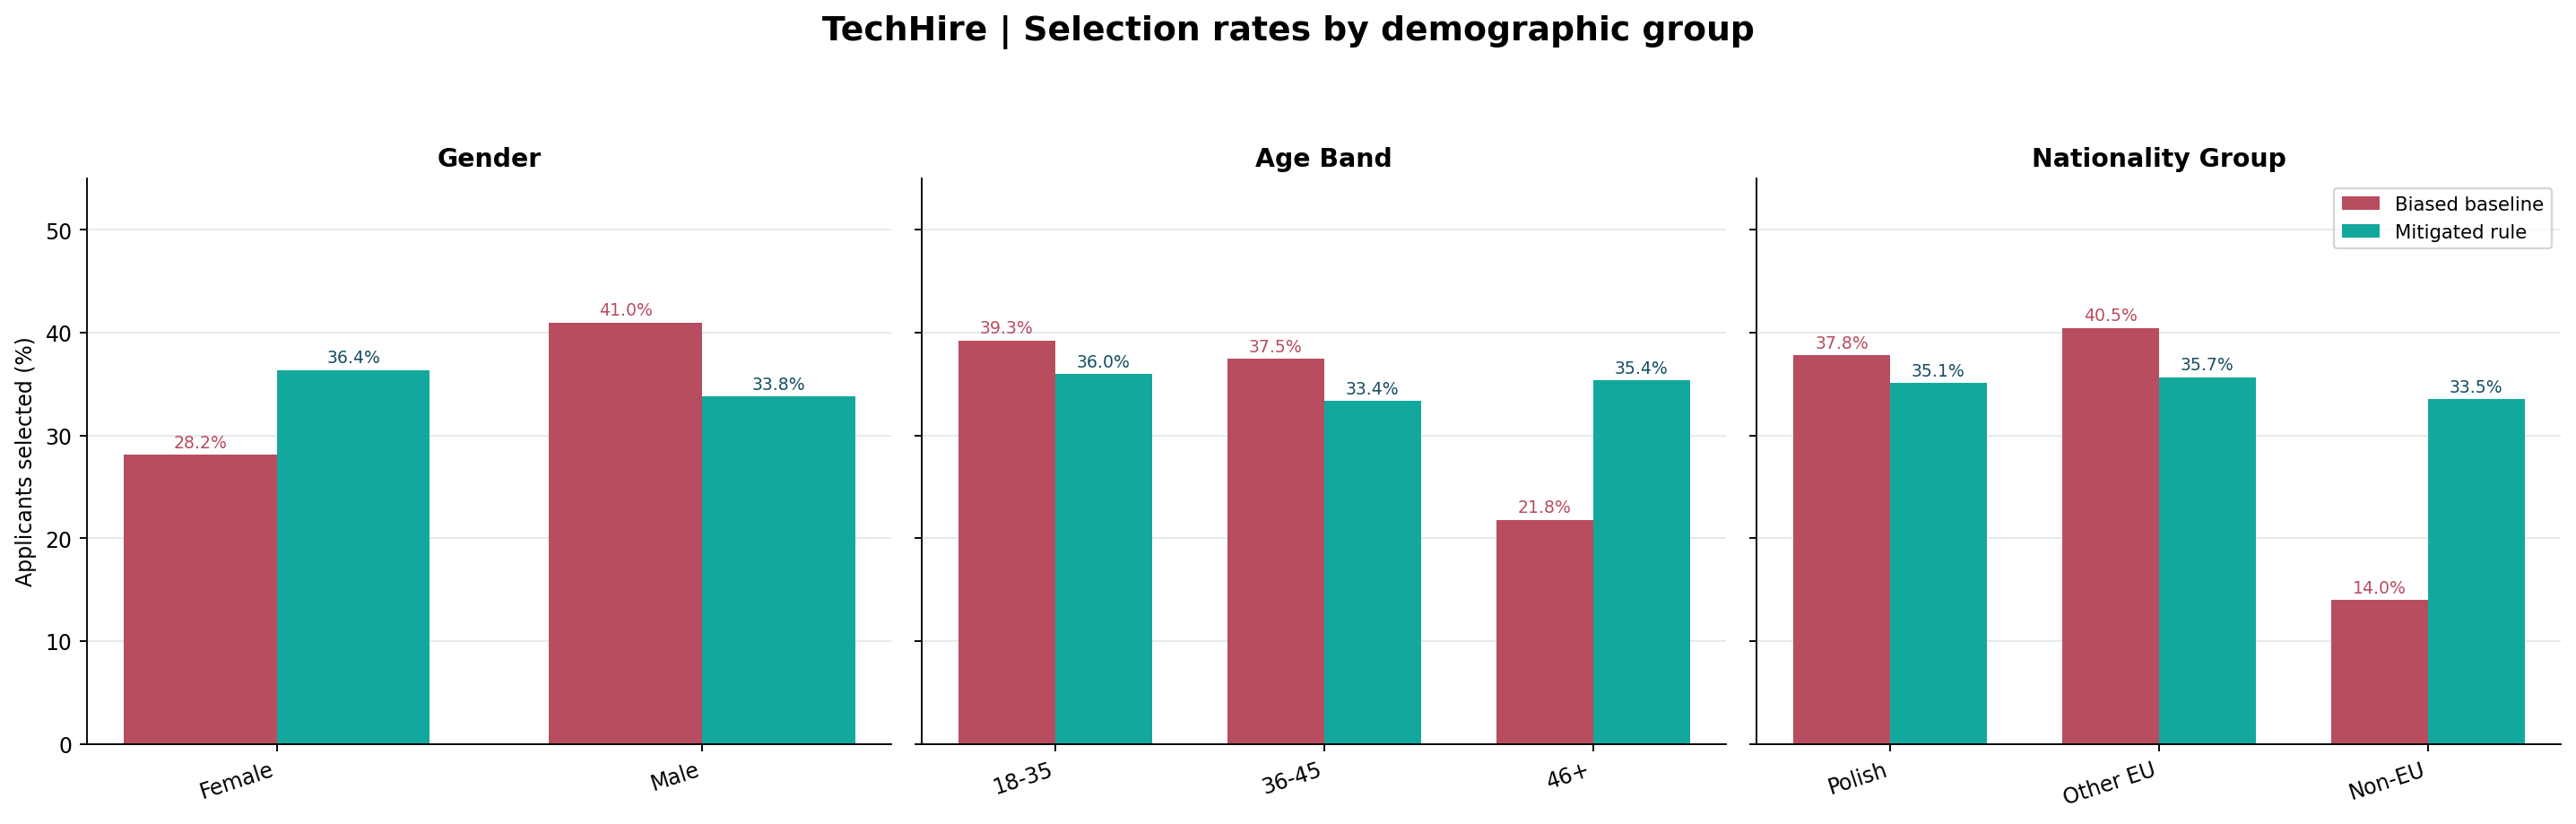

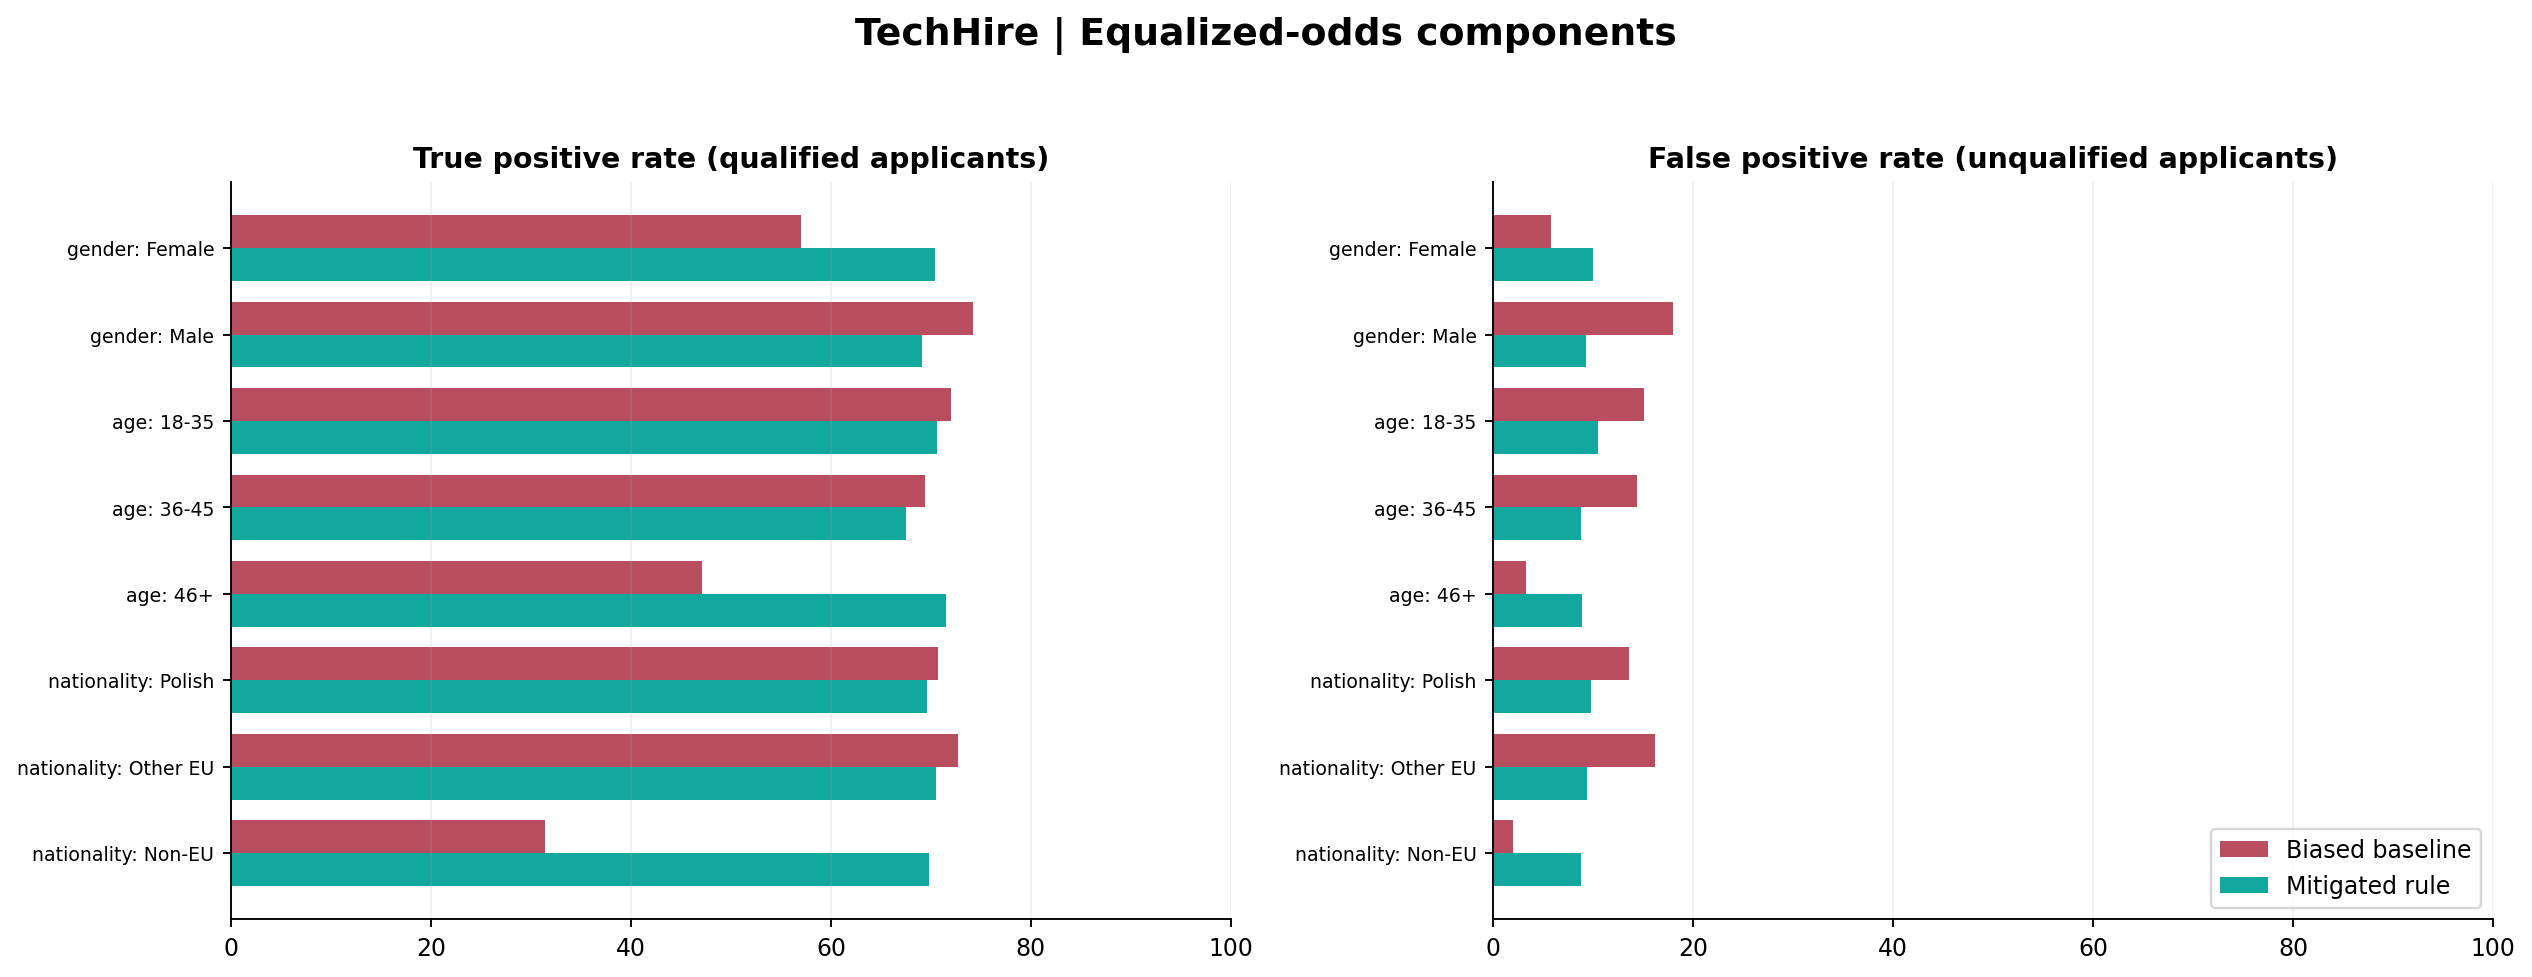

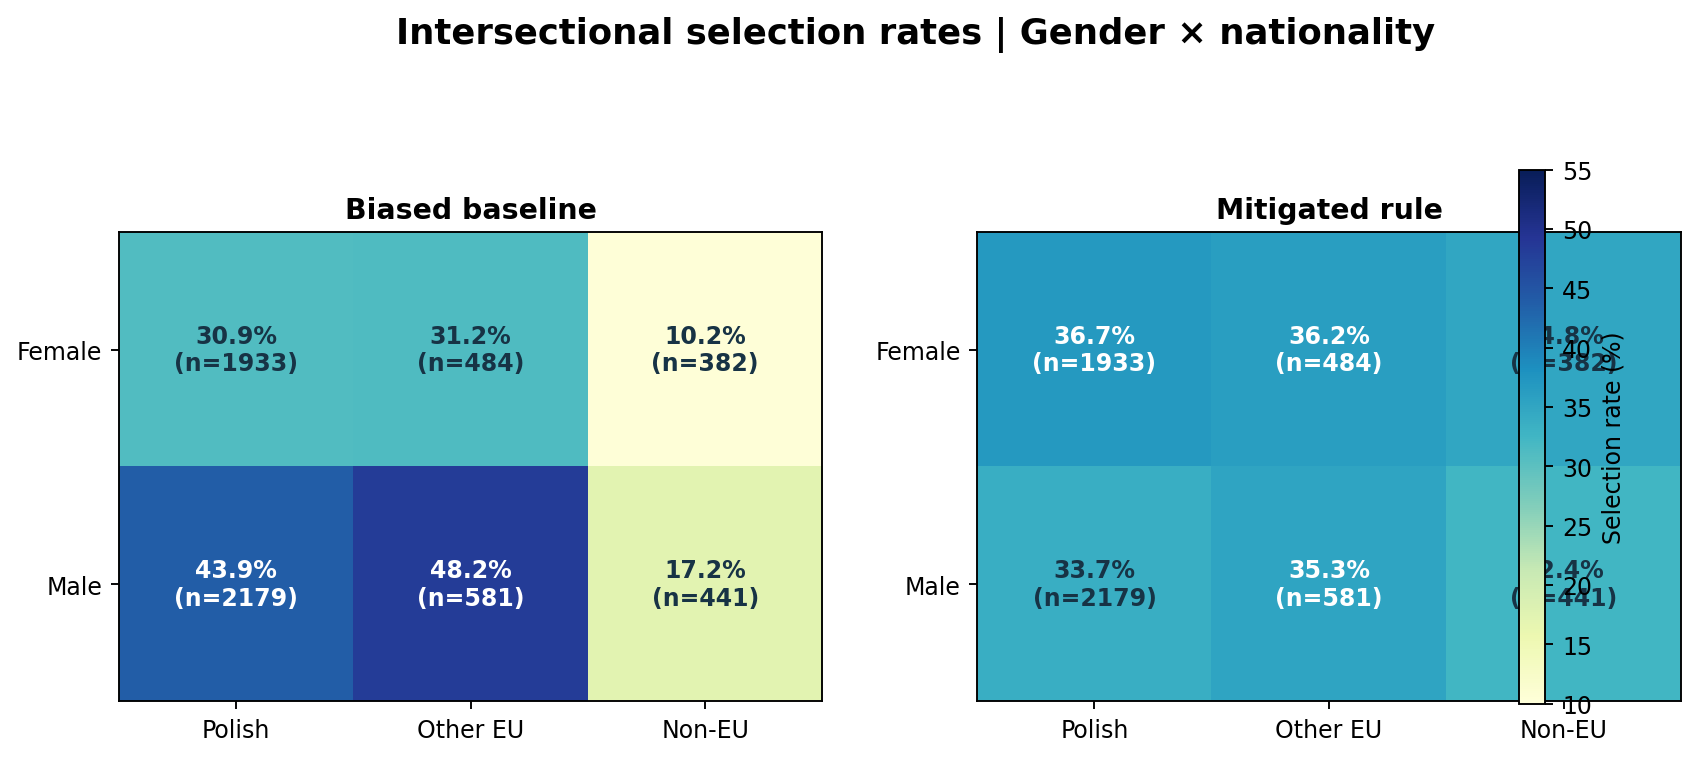

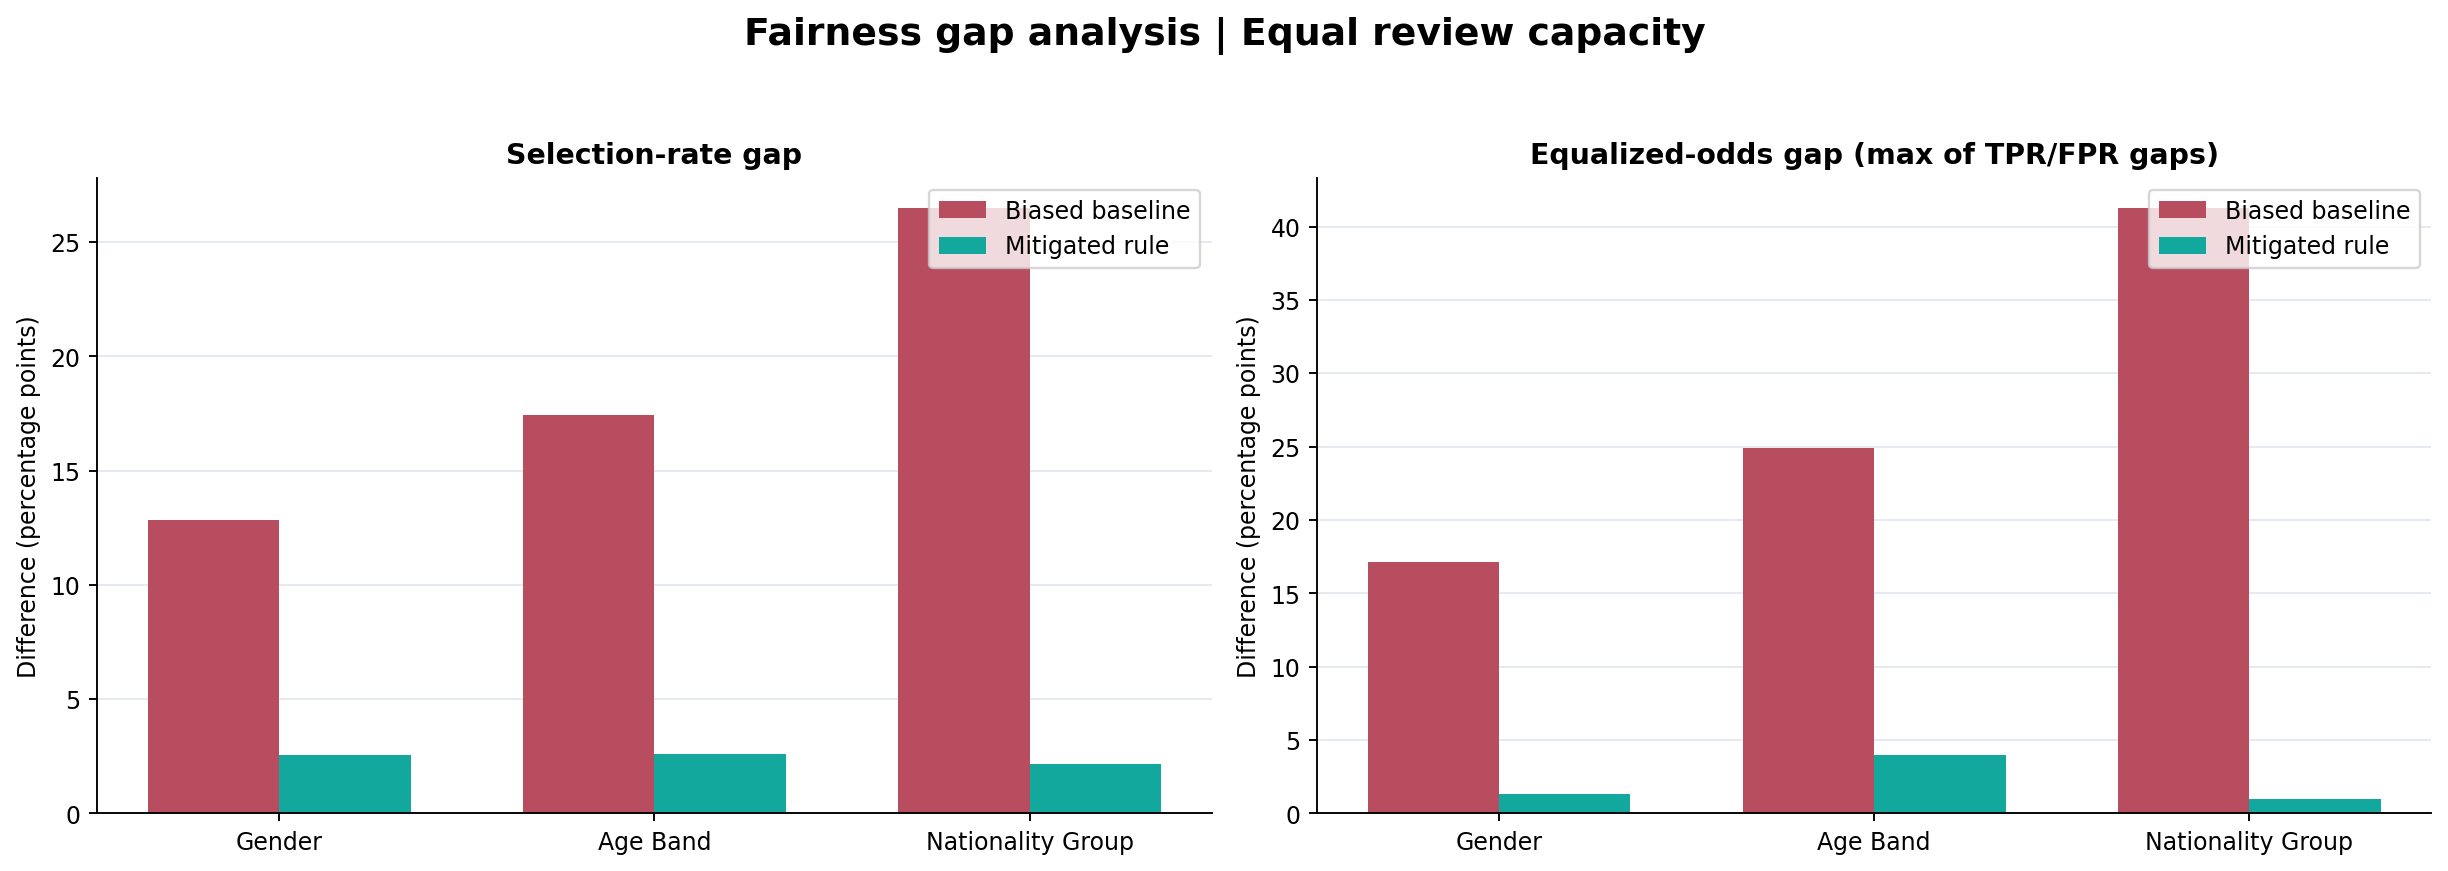

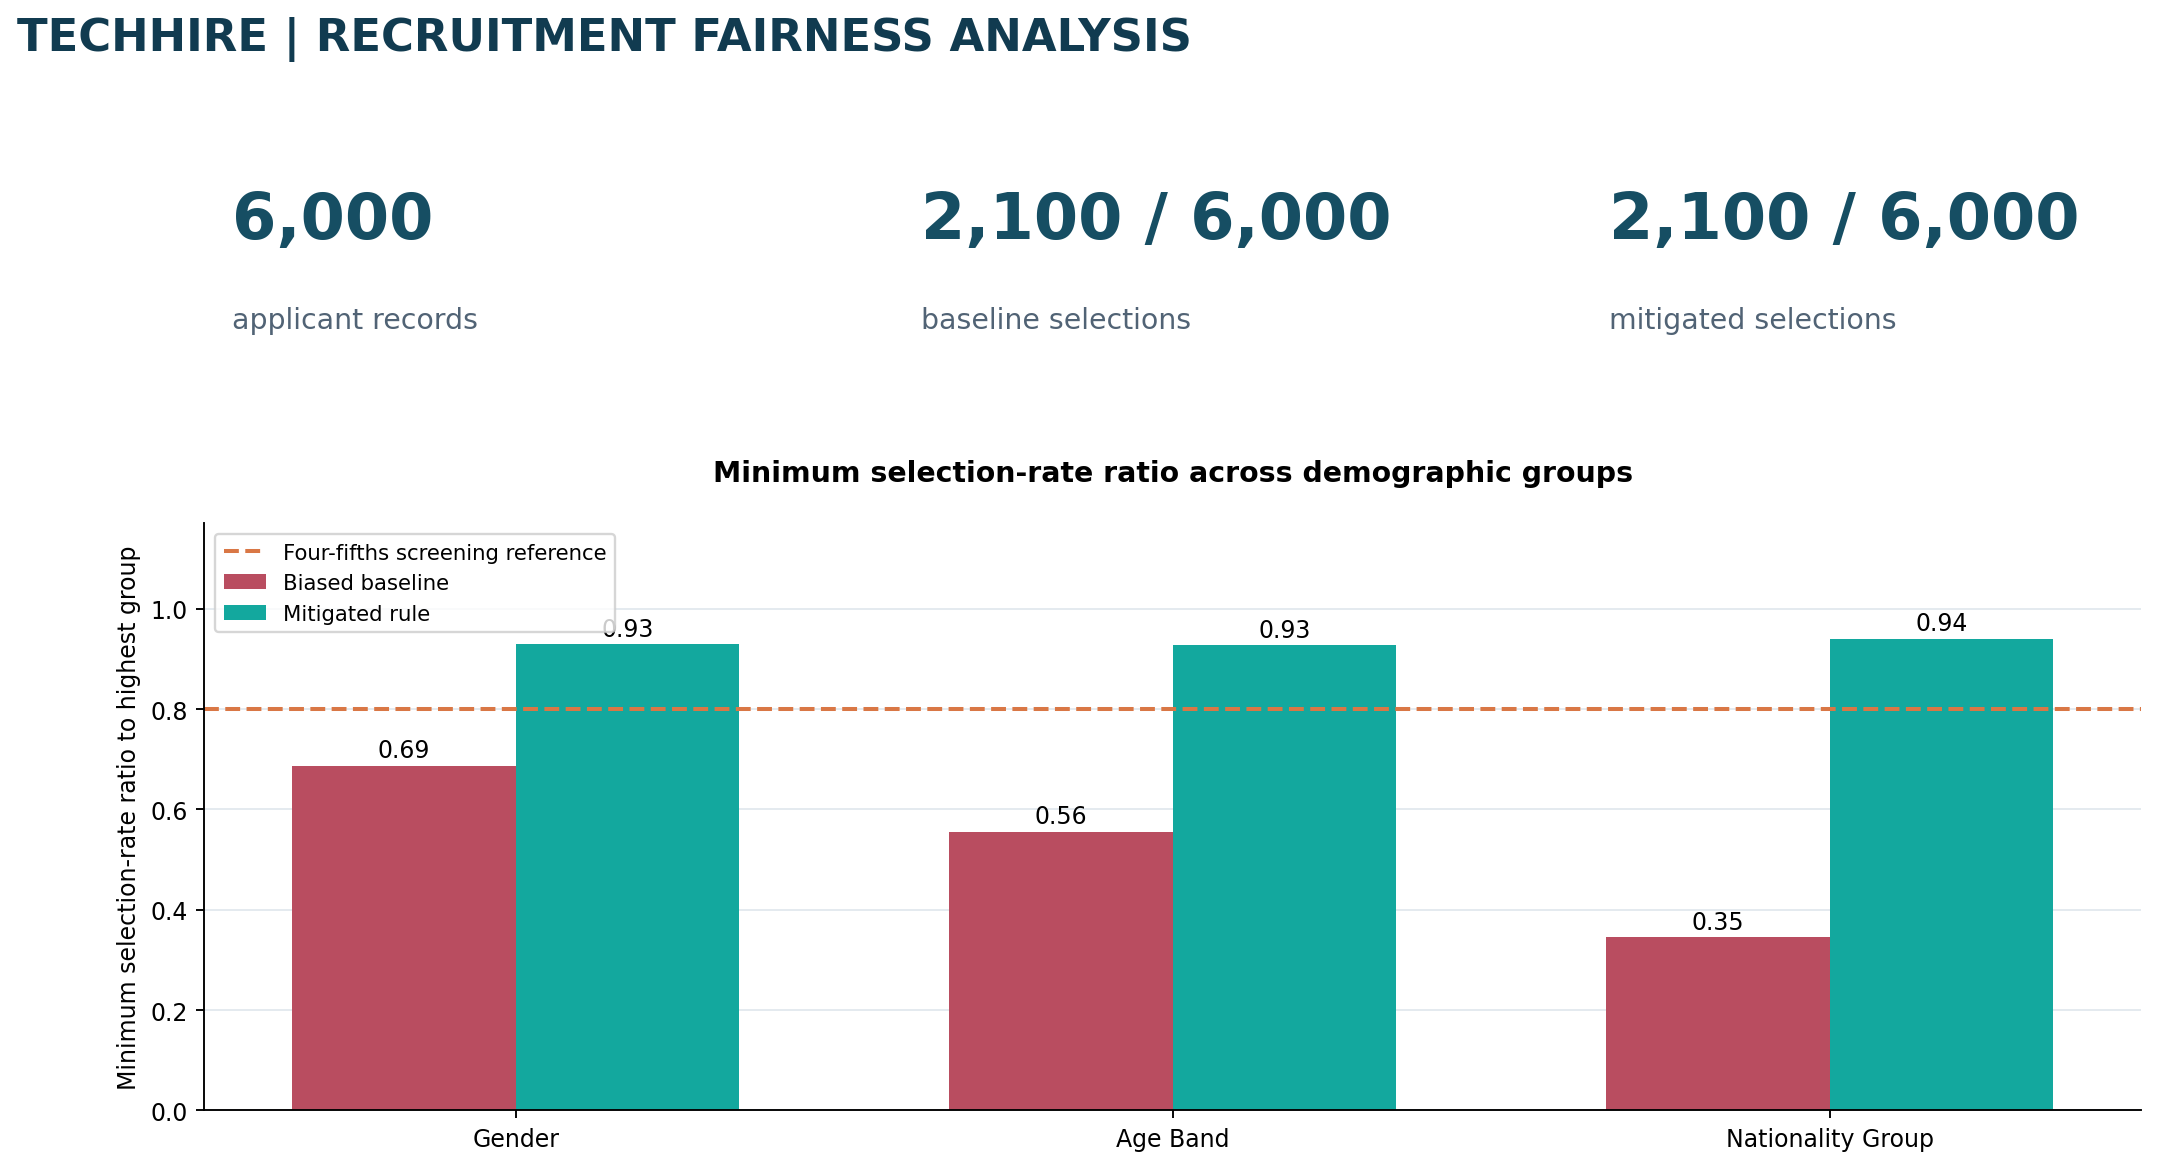

In [6]:
files = generate_figures(applicants,metrics,summary,RESULTS_DIR)
print("Saved charts:", *files, sep="\n - ")
for filename in files:
    display(Image(filename=str(RESULTS_DIR / filename), width=900))

## Step 6 — Governance assessment

The revised rule narrows group-level selection and error-rate gaps at the same screening capacity. Recommended next steps include validating the qualification definition, examining business utility, reviewing selection criteria, and establishing monitoring and escalation for material disparities.


In [7]:
print("RECRUITMENT FAIRNESS — GOVERNANCE CHECK")
print("Applicant count:",len(applicants))
print("Direct identifier field check:", "PASS" if all(c not in applicants.columns for c in ["name","email","phone","address"]) else "REVIEW")
print("Fixed selection capacity:",int(applicants.baseline_selected.sum()),int(applicants.mitigated_selected.sum()))
print("Min selection ratios (baseline -> mitigated):")
for attribute in ["gender","age_band","nationality_group"]:
    subset=summary[summary.attribute==attribute].set_index("scenario")
    print(f"{attribute}: {subset.loc['Baseline','min_selection_ratio']:.3f} -> {subset.loc['Mitigated','min_selection_ratio']:.3f}")

RECRUITMENT FAIRNESS — GOVERNANCE CHECK
Applicant count: 6000
Direct identifier field check: PASS
Fixed selection capacity: 2100 2100
Min selection ratios (baseline -> mitigated):
gender: 0.687 -> 0.929
age_band: 0.556 -> 0.928
nationality_group: 0.345 -> 0.940


## Data scope and limitations

The 6,000 applicant records and both ranking policies are generated for this controlled recruitment-fairness experiment. Results describe the simulated cohort, not observed TechHire hiring decisions or real-world remediation effectiveness. The earlier governance workbook contains separate case assumptions; deployment decisions would require validated applicant data, outcome labels, and independent review.